## Data Cleaning and Preparation

Setting up environment for Spark

References:
https://docs.python.org/3/library/pathlib.html - for working with paths
https://www.geeksforgeeks.org/deep-learning/convolutional-neural-network-cnn-in-tensorflow/ - for the CNN model creation

In [1]:
import os, sys
os.environ["JAVA_HOME"] = os.path.join(sys.prefix, "Library")
os.environ["PATH"] = os.path.join(sys.prefix, "Library", "bin") + os.pathsep + os.environ["PATH"]
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

Imports

In [ ]:
import pandas as pd
import numpy as np
import random
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import(
    Input,
    Conv2D,
    MaxPooling2D,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import os
from pathlib import Path
from PIL import Image, ImageFile
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import pyspark
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

# Assisted by ChatGPT
# Setting up the paths so that we use the folder that the notebook is run from
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "merged_dataset.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT
TRAIN_DIR = DATA_DIR / "Training Data"
TEST_DIR = DATA_DIR / "Testing Data"
VAL_DIR = DATA_DIR / "Validation Data"

OUTPUT_DIR = PROJECT_ROOT / "output"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = (180, 180)
BATCH_SIZE = 32
RANDOM_STATE = 42

CLASS_NAMES = [
    "Mountain",
    "Glacier",
    "Forest",
    "Desert",
    "Coast"
]



In [4]:
def count_images(directory):#Counting the images in each class folder
    results = {}

    for category in CLASS_NAMES:
        category_path = directory / category

        if category_path.exists():
            image_count = len([
                file for file in category_path.iterdir()
                if file.is_file()
            ])

            results[category] = image_count

        else:
            results[category] = 0
    return results
#Counting the images in each of the three original folders
train_counts = count_images(TRAIN_DIR)
val_counts = count_images(VAL_DIR)
test_counts = count_images(TEST_DIR)

#Combining the counts into one table
image_distribution = pd.DataFrame({
    "Training": train_counts,
    "Validation": val_counts,
    "Testing": test_counts
})

print(image_distribution)

          Training  Validation  Testing
Mountain      2000         300      100
Glacier       2000         300      100
Forest        2000         300      100
Desert        2000         300      100
Coast         2000         300      100


In [5]:
data = pd.read_csv(DATA_DIR / "merged_dataset.csv")#Loading the merged dataset
data.head()

,rel_path,filename,label,original_split,extension,size_bytes,md5,width,height,mode,format,is_corrupt
0,Training Data/Coast/Coast-Train (1).jpeg,Coast-Train (1).jpeg,Coast,Training,.jpeg,6089,e764538413827d08d6b9291cc92fa7b1,275,183,RGB,JPEG,False
1,Training Data/Coast/Coast-Train (10).jpeg,Coast-Train (10).jpeg,Coast,Training,.jpeg,5898,2ebeaadf42a1566e6e9caedd233f323e,300,168,RGB,JPEG,False
2,Training Data/Coast/Coast-Train (100).jpeg,Coast-Train (100).jpeg,Coast,Training,.jpeg,12894,8f9c16e90f06b6d291e8596efcde63ca,275,183,RGB,JPEG,False
3,Training Data/Coast/Coast-Train (1000).jpeg,Coast-Train (1000).jpeg,Coast,Training,.jpeg,10087,429b4107b90f2daab4d9d1f1554ad966,275,183,RGB,JPEG,False
4,Training Data/Coast/Coast-Train (1001).jpeg,Coast-Train (1001).jpeg,Coast,Training,.jpeg,9286,877e7d1b3867359c84dd25c861c6cb24,300,168,RGB,JPEG,False


In [6]:
data.shape#Checking the shape of the dataset

(12000, 12)

In [7]:
data.info()#Checking column names, data types, null counts

<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   rel_path        12000 non-null  str  
 1   filename        12000 non-null  str  
 2   label           12000 non-null  str  
 3   original_split  12000 non-null  str  
 4   extension       12000 non-null  str  
 5   size_bytes      12000 non-null  int64
 6   md5             12000 non-null  str  
 7   width           12000 non-null  int64
 8   height          12000 non-null  int64
 9   mode            12000 non-null  str  
 10  format          12000 non-null  str  
 11  is_corrupt      12000 non-null  bool 
dtypes: bool(1), int64(3), str(8)
memory usage: 2.5 MB


In [8]:
data.isnull().sum()#counting missing values in every column

rel_path          0
filename          0
label             0
original_split    0
extension         0
size_bytes        0
md5               0
width             0
height            0
mode              0
format            0
is_corrupt        0
dtype: int64

In [9]:
data.duplicated().sum()#Checking for any fully duplicated rows

np.int64(0)

Checking for any conflicting labels

In [10]:
#Finding identical images that have different labels
label_conflicts = (
    data.groupby("md5")["label"]
    .nunique()
)

conflicting_hashes = label_conflicts[#Checking for hashes that appear under more than one label
    label_conflicts > 1
].index

conflicts = data[#Sorting all conflicting rows so that they sit together
    data["md5"].isin(conflicting_hashes)
].sort_values("md5")

len(conflicting_hashes)

print(conflicts[# Showing conflicting files and where they come from
    ["filename", "label", "original_split", "md5"]
    ])

                        filename     label original_split  \
5236     Forest-Train (310).jpeg    Forest       Training   
8365        Mountain (3341).jpeg  Mountain       Training   
6965   Glacier-Train (1868).jpeg   Glacier       Training   
8187        Mountain (3163).jpeg  Mountain       Training   
9709        Mountain (4685).jpeg  Mountain       Training   
4179     Forest-Train (116).jpeg    Forest       Training   
8543        Mountain (3519).jpeg  Mountain       Training   
5490      Forest-Train (54).jpeg    Forest       Training   
9062        Mountain (4038).jpeg  Mountain       Training   
9652        Mountain (4628).jpeg  Mountain       Training   
10803    Forest-Valid (282).jpeg    Forest     Validation   
5676     Forest-Train (707).jpeg    Forest       Training   
9835        Mountain (4811).jpeg  Mountain       Training   
6959   Glacier-Train (1862).jpeg   Glacier       Training   
10037     Coast-Valid (132).jpeg     Coast     Validation   
3726     Desert-Train (7

Removing conflicting labels

In [11]:
data_clean = data.copy()#Making a copy of the dataset so that the original stays untouched

label_conflicts = (
    data_clean.groupby("md5")["label"].nunique()
)

conflicting_hashes = label_conflicts[
    label_conflicts > 1
].index

data_clean = data_clean[#Dropping every copy of a conflicting image
    ~data_clean["md5"].isin(conflicting_hashes)
].copy()

split_priority = {#Ordering the sets for duplicate removal
    "Training": 0,
    "Validation": 1,
    "Testing": 2
}

data_clean["split_priority"] = data_clean["original_split"].map(split_priority)

data_clean = data_clean.sort_values(by=["split_priority"])

data_clean = data_clean.drop(columns=["split_priority"])

print("Original", len(data))
print("Cleaned", len(data_clean))

Original 12000
Cleaned 11976


Removing any exact duplicate images

In [ ]:
before = len(data_clean)

data_clean = data_clean.drop_duplicates(
    subset="md5",
    keep="first"#Keeping only the first copy 
).copy()

data_clean.reset_index(drop=True, inplace=True)#Renumbering rows after duplicate removal


Checking Image Quality and removing corrupt or missing images

In [13]:
missing_files = []
corrupt_files = []

for index, row in data_clean.iterrows():
    image_path = PROJECT_ROOT / row["rel_path"]#Building hte full path from the project folder

    if not image_path.exists():#Record files in the csv that are no longer on teh disk
        missing_files.append(row["rel_path"])
        continue

    try:# Checking file structure
        with Image.open(image_path) as img:
            img.verify()
    except Exception:# Checking if file is damaged or invalid
        corrupt_files.append(row["rel_path"])

print("Missing files:", len(missing_files))
print("Corrupt files:", len(corrupt_files))

Missing files: 0
Corrupt files: 0


Removing corrupt files

In [14]:
invalid_files = missing_files + corrupt_files

data_clean = data_clean[#Removing any invalid files
    ~data_clean["rel_path"].isin(invalid_files)
].copy()

data_clean.reset_index(drop=True, inplace=True)#resetting the numbering again

print("Final dataset shape:", data_clean.shape)#showing the size of the final, cleaned dataset

Final dataset shape: (11657, 12)


Checking Image dimensions and colour modes

In [15]:
print("Image Dimensions:")#Printing the image dimensions
print(data_clean[["width", "height"]].describe())

print("\nColour Modes")#Printing the image colour modes
print(data_clean["mode"].value_counts())

print("\nImage Formats")#Printing the image formats
print(data_clean["format"].value_counts())

Image Dimensions:
              width        height
count  11657.000000  11657.000000
mean     272.104830    189.555117
std       40.600775     33.030342
min      133.000000     94.000000
25%      262.000000    173.000000
50%      275.000000    183.000000
75%      291.000000    193.000000
max      537.000000    347.000000

Colour Modes
mode
RGB    11657
Name: count, dtype: int64

Image Formats
format
JPEG    11657
Name: count, dtype: int64


Preparation

In [ ]:
data_clean["image_path"] = data_clean["rel_path"].apply(lambda x: PROJECT_ROOT / x)#Adding full path to images so they can be loaded later

encoding class names

In [17]:
class_names = ["Mountain", "Glacier", "Forest", "Desert", "Coast"]

label_mapping = {#Mapping the labels
    label: index for index, label in enumerate(class_names)
}

data_clean["encoded_labels"] = data_clean["label"].map(label_mapping)
print(label_mapping)#Showing the encoded labels

{'Mountain': 0, 'Glacier': 1, 'Forest': 2, 'Desert': 3, 'Coast': 4}


Creating image-loading pipeline

In [ ]:
data_clean["image_path"] = data_clean["image_path"].apply(#Converting to text so TensorFlow can read the file paths
    lambda x: str(x)
)


Creating the image loading pipeline that reads images from the disk then prepares it for the CNN
(https://www.tensorflow.org/tutorials/load_data/images)

In [ ]:
def load_image(image_path, label):
    image = tf.io.read_file(image_path)

    image = tf.io.decode_jpeg(#Decoding the image to a 3-channel tensor of pixel values
        image,
        channels = 3
    )

    image = tf.image.resize(#Resizing to a fixed input size 
        image,
        IMAGE_SIZE
    )

    image = image / 255.0#Scaling pixel values

    return image, label

#Building a pipeline for one split of the cleaned data
def create_dataset(split, shuffle=False):
    split_data = data_clean[
        data_clean["original_split"] == split#Selecting rows that belong to the split
    ]

    image_paths = split_data["image_path"].values
    labels = split_data["encoded_labels"].values

    dataset = tf.data.Dataset.from_tensor_slices(#Pairing image paths with their label
        (image_paths, labels)
    )

    if shuffle:#Shuffle images so the model doesn't see them in order
        dataset = dataset.shuffle(
            buffer_size=len(split_data),
            seed=42
        )

    dataset = dataset.map(#Load and process the images in parallel
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )  

    dataset = dataset.batch(BATCH_SIZE)#Grouping images into batches
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

train_dataset = create_dataset("Training", shuffle=True)#Only the training data is shuffled
val_dataset = create_dataset("Validation")
test_dataset = create_dataset("Testing")

## Exploratory Data Analysis

Starting the spark session

In [21]:
spark = SparkSession.builder \
    .appName("Scenery_Image_EDA") \
    .getOrCreate()

print("Spark Version:", spark.version)

c:\Users\Jesse-LeeWeeder\.conda\envs\spark_env\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Spark Version: 4.2.0


Selecting the columns needed for the EDA

In [22]:
eda_data = data_clean[
    [
        "filename",
        "label",
        "original_split",
        "width",
        "height",
        "size_bytes",
        "format",
        "mode"
    ]
].copy()

spark_data = spark.createDataFrame(eda_data)#Converting the dataset into a spark data frame

spark_data.printSchema()

spark_data.show(5, truncate=False)

print("Total Images: ", spark_data.count())

c:\Users\Jesse-LeeWeeder\.conda\envs\spark_env\Lib\site-packages\pyspark\sql\pandas\conversion.py:659: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
c:\Users\Jesse-LeeWeeder\.conda\envs\spark_env\Lib\site-packages\pyspark\sql\pandas\conversion.py:936: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


root
 |-- filename: string (nullable = true)
 |-- label: string (nullable = true)
 |-- original_split: string (nullable = true)
 |-- width: long (nullable = true)
 |-- height: long (nullable = true)
 |-- size_bytes: long (nullable = true)
 |-- format: string (nullable = true)
 |-- mode: string (nullable = true)

+-----------------------+-----+--------------+-----+------+----------+------+----+
|filename               |label|original_split|width|height|size_bytes|format|mode|
+-----------------------+-----+--------------+-----+------+----------+------+----+
|Coast-Train (1).jpeg   |Coast|Training      |275  |183   |6089      |JPEG  |RGB |
|Coast-Train (10).jpeg  |Coast|Training      |300  |168   |5898      |JPEG  |RGB |
|Coast-Train (100).jpeg |Coast|Training      |275  |183   |12894     |JPEG  |RGB |
|Coast-Train (1000).jpeg|Coast|Training      |275  |183   |10087     |JPEG  |RGB |
|Coast-Train (1001).jpeg|Coast|Training      |300  |168   |9286      |JPEG  |RGB |
+---------------------

In [23]:
spark_data.describe(#Showing a summary of the statistics for the numeric image properties
    "width",
    "height",
    "size_bytes"
).show()

+-------+------------------+------------------+------------------+
|summary|             width|            height|        size_bytes|
+-------+------------------+------------------+------------------+
|  count|             11657|             11657|             11657|
|   mean|272.10482971605046|189.55511709702324| 9463.482113751394|
| stddev| 40.60077523138882| 33.03034216504956|3459.6692790092193|
|    min|               133|                94|              1691|
|    max|               537|               347|             32618|
+-------+------------------+------------------+------------------+



Analysing class distribution

In [24]:
#Showing the count of all images in each class in descending order
class_dist = spark_data.groupBy("label") \
    .count() \
    .orderBy(F.desc("count"))

class_dist.show()

+--------+-----+
|   label|count|
+--------+-----+
|   Coast| 2395|
| Glacier| 2341|
|  Forest| 2330|
|  Desert| 2313|
|Mountain| 2278|
+--------+-----+



In [25]:
dist_percent = spark_data.count()

class_dist = class_dist.withColumn(#Making a percentage for the counts
    "percentage",
    F.round((F.col("count") / dist_percent) * 100, 2)
)

class_dist.show()

+--------+-----+----------+
|   label|count|percentage|
+--------+-----+----------+
|   Coast| 2395|     20.55|
| Glacier| 2341|     20.08|
|  Forest| 2330|     19.99|
|  Desert| 2313|     19.84|
|Mountain| 2278|     19.54|
+--------+-----+----------+



c:\Users\Jesse-LeeWeeder\.conda\envs\spark_env\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


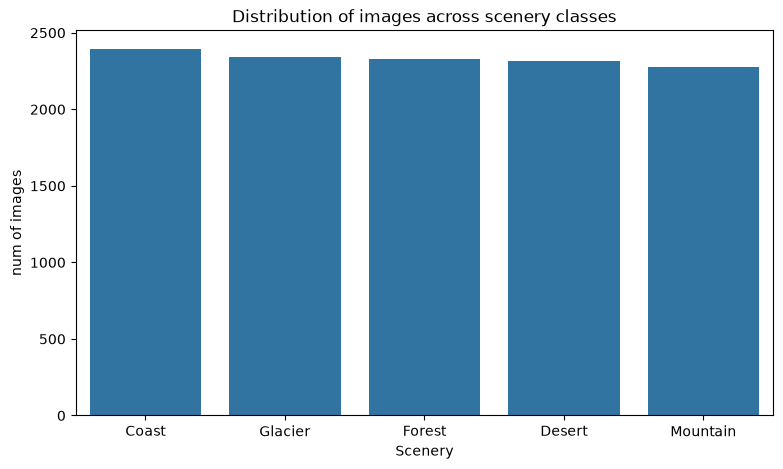

In [26]:
class_pd = class_dist.toPandas()#Bringing the class distribution back to pandas

plt.figure(figsize=(9, 5))

sns.barplot(#Plotting the distribution of the images
    data=class_pd,
    x="label",
    y="count"
)

plt.title("Distribution of images across scenery classes")
plt.xlabel("Scenery")
plt.ylabel("num of images")
plt.tight_layout
plt.show()

Investigating the distribution across the original splits

In [27]:
#Counting the images from each original folder
split_dist = spark_data.groupBy("original_split") \
    .count() \
    .orderBy("original_split")

split_dist.show()

#Calculating the percent of each split
split_dist = split_dist.withColumn(
    "percentage",
    F.round(
        (F.col("count") / dist_percent) * 100, 2
    )
)

split_dist.show()

+--------------+-----+
|original_split|count|
+--------------+-----+
|       Testing|  445|
|      Training| 9771|
|    Validation| 1441|
+--------------+-----+

+--------------+-----+----------+
|original_split|count|percentage|
+--------------+-----+----------+
|       Testing|  445|      3.82|
|      Training| 9771|     83.82|
|    Validation| 1441|     12.36|
+--------------+-----+----------+



c:\Users\Jesse-LeeWeeder\.conda\envs\spark_env\Lib\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


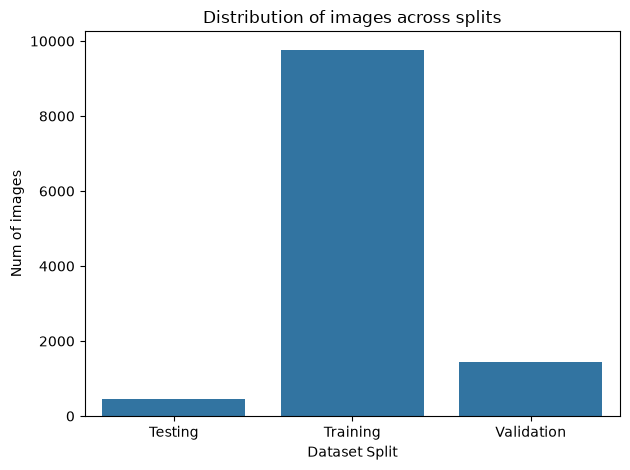

In [28]:
split_pd = split_dist.toPandas()

plt.Figure(figsize=(8, 5))

sns.barplot(#Plotting the distribution of images across the splits
    data=split_pd,
    x="original_split",
    y="count"
)

plt.title("Distribution of images across splits")
plt.xlabel("Dataset Split")
plt.ylabel("Num of images")
plt.tight_layout()
plt.show()

Investigating the relationships between image dimensions

In [29]:
data_dimensions = spark_data.withColumn(#Creating aspect ratios from width/height
    "aspect_ratios",
    F.col("width") / F.col("height")
)

data_dimensions.select(#Showing the average, minimum and maximum aspect ratios
    F.round(F.avg("aspect_ratios"), 3).alias("average_aspect_ratio"),
    F.round(F.min("aspect_ratios"), 3).alias("minimum_aspect_ratio"),
    F.round(F.max("aspect_ratios"), 3).alias("maximum_aspect_ratio")
).show()

+--------------------+--------------------+--------------------+
|average_aspect_ratio|minimum_aspect_ratio|maximum_aspect_ratio|
+--------------------+--------------------+--------------------+
|               1.504|               0.418|               5.713|
+--------------------+--------------------+--------------------+



In [30]:
data_dimensions = data_dimensions.withColumn(#Categorising images based on their orientation
    "orientation",
    F.when(F.col("width") > F.col("height"), "Landscape")
    .when(F.col("width") < F.col("height"), "Portrait")
    .otherwise("Square")
)

image_orientation = data_dimensions.groupBy(#Counting images in each orientation
    "orientation"
).count().orderBy(F.desc("count"))

image_orientation.show()

+-----------+-----+
|orientation|count|
+-----------+-----+
|  Landscape|10147|
|   Portrait| 1228|
|     Square|  282|
+-----------+-----+



## Model Creation

References:
* https://www.geeksforgeeks.org/deep-learning/convolutional-neural-network-cnn-in-tensorflow/
* https://www.tensorflow.org/tutorials/images/cnn

In [32]:
cnn_model = Sequential([
    Input(shape=(180, 180, 3)),#The input should be 180x180 pixels with 3 colour channels

    Conv2D(32, (3, 3), activation="relu"),#Convolution layer 1
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, (3, 3), activation="relu"),#Convolution layer 2
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(128, (3, 3), activation="relu"),#Convolution layer 3
    MaxPooling2D(pool_size=(2, 2)),

    GlobalAveragePooling2D(),#Averaging each feature map down to one value
    Dense(128, activation="relu"),#Fully connected layer
    Dropout(0.5),#Randomly switching off 50% of neurons

    Dense(5, activation="softmax")#output layer
])

cnn_model.summary()#Creating a summary of the models architecture


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,405 (431.27 KB)

 Trainable params: 110,405 (431.27 KB)

 Non-trainable params: 0 (0.00 B)

In [33]:
cnn_model.compile(#Compiling the model
    optimizer=Adam(learning_rate=0.001),#Adam optimiser with a starting learning rate of 0.001
    loss="sparse_categorical_crossentropy",#Used to examine the loss
    metrics=["accuracy"]
)

Overfitting Reduction

In [ ]:
early_stopping = EarlyStopping(#Stopping training once loss has not improved after 5 consecutive epochs
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(#Dividing the learning rate by 2 when validation loss stalls for 2 epochs
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

Model Training

In [35]:
results = cnn_model.fit(#Training the model
    train_dataset,#Training on the training data
    validation_data=val_dataset,
    epochs=20,#Trained for 20 epochs
    callbacks=[
        early_stopping,
        reduce_lr
    ],
    verbose=1
)

Epoch 1/20


c:\Users\Jesse-LeeWeeder\.conda\envs\spark_env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


306/306 ━━━━━━━━━━━━━━━━━━━━ 66s 205ms/step - accuracy: 0.5471 - loss: 1.1111 - val_accuracy: 0.5753 - val_loss: 1.0227 - learning_rate: 0.0010
Epoch 2/20
306/306 ━━━━━━━━━━━━━━━━━━━━ 69s 224ms/step - accuracy: 0.6167 - loss: 0.9835 - val_accuracy: 0.6044 - val_loss: 0.9760 - learning_rate: 0.0010
Epoch 3/20
306/306 ━━━━━━━━━━━━━━━━━━━━ 80s 218ms/step - accuracy: 0.6325 - loss: 0.9400 - val_accuracy: 0.6384 - val_loss: 0.9408 - learning_rate: 0.0010
Epoch 4/20
306/306 ━━━━━━━━━━━━━━━━━━━━ 69s 226ms/step - accuracy: 0.6512 - loss: 0.8993 - val_accuracy: 0.6447 - val_loss: 0.9226 - learning_rate: 0.0010
Epoch 5/20
306/306 ━━━━━━━━━━━━━━━━━━━━ 71s 230ms/step - accuracy: 0.6626 - loss: 0.8683 - val_accuracy: 0.6523 - val_loss: 0.9122 - learning_rate: 0.0010
Epoch 6/20
306/306 ━━━━━━━━━━━━━━━━━━━━ 69s 225ms/step - accuracy: 0.6769 - loss: 0.8492 - val_accuracy: 0.6447 - val_loss: 0.8970 - learning_rate: 0.0010
Epoch 7/20
306/306 ━━━━━━━━━━━━━━━━━━━━ 69s 224ms/step - accuracy: 0.6819 - loss:

## Model Evaluation

Providing the loss and accuracy on the test set

In [37]:
test_loss, test_acc = cnn_model.evaluate(test_dataset)

print(test_loss)
print(test_acc)

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 82ms/step - accuracy: 0.7506 - loss: 0.6121
0.6121377944946289
0.7505617737770081


Creating a confusion matrix

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 86ms/step


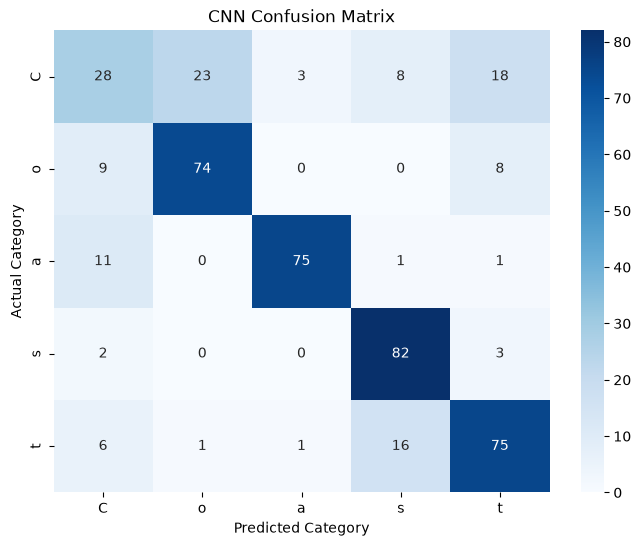

In [38]:
y_true = np.concatenate([#Collecting the true labels for every batch of the test set
    labels.numpy() for images, labels in test_dataset
])

y_prob = cnn_model.predict(test_dataset)#Predicting class probabilities
y_pred = np.argmax(y_prob, axis=1)#Taking the most likely class for each image

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("CNN Confusion Matrix")
plt.show()

In [ ]:
class_names = [#Recreating class names for the classification report
    "Mountain",
    "Glacier",
    "Forest",
    "Desert",
    "Coast"
]

Creating classification report

In [41]:
print(classification_report(#Creating the classification report
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

    Mountain       0.50      0.35      0.41        80
     Glacier       0.76      0.81      0.78        91
      Forest       0.95      0.85      0.90        88
      Desert       0.77      0.94      0.85        87
       Coast       0.71      0.76      0.74        99

    accuracy                           0.75       445
   macro avg       0.74      0.74      0.73       445
weighted avg       0.74      0.75      0.74       445

